Lehet mást ad:

sűrűség meleg helyen kisebb, hidegen nagyobb, akár figyelembe lehetne venni

3d-en is lehetne csinálni nem csak 2d-ben, hiszen a hideg leszáll

Kérdések:
    

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from ipywidgets import *
import imageio
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
class heatcapacity: #this is the class of the "map" of the room, this way it is easy to add any "object" to the map
    def __init__(self,size,C_wall,C_rad,C_air,C_window):
        self.size=size
        self.matrix=np.full((size,size),C_air) #we fill the whole room with air, that is the base material
    def wall(self,row,column): #creates a wall cell at [row][column]
        self.matrix[row][column]=C_wall
    def radiator(self,row,column): ##creates a radiator cell at [row][column]
        self.matrix[row][column]=C_rad
    def window(self,row,column): #creates a window cell at [row][column]
        self.matrix[row][column]=C_window
    def air(self,row,column): #creates an air cell at [row][column], for simplicity of generating some maps
        self.matrix[row][column]=C_air

def initaltemp(heatcapacity,Cvect,Twall,Tair,Twindow,Trad):
    C_air=Cvect[0]; C_wall=Cvect[1]; C_rad=Cvect[2]; C_window=Cvect[3]
    T0=np.zeros((len(heatcapacity),len(heatcapacity)))
    for i in range(len(heatcapacity)): #creates a matrix with the wanted starting temperatures
        for j in range(len(heatcapacity)):
            if heatcapacity[i][j]==C_wall: #wall
                T0[i][j]=Twall
            elif heatcapacity[i][j]==C_rad: #radiator
                T0[i][j]=Trad
            elif heatcapacity[i][j]==C_air: #air
                T0[i][j]=Tair
            elif heatcapacity[i][j]==C_window: #window
                T0[i][j]=Twindow
    return T0 #gives the starting temperature matrix as output

def heattransfer_horiz(heatcapacity,Cvect,heattransf): #
    #this function creates the heat transfer matrix that contains the heat transfer ratios between neighbouring cells, depending on the materials in the cells
    rad_wall=heattransf[5]; air_wall=heattransf[3]; rad_air=heattransf[4]; air_air=heattransf[0]; wall_wall=heattransf[1]; rad_rad=heattransf[2]
    air_window=heattransf[6]; wall_window=heattransf[7]; rad_window=heattransf[8]; window_window=heattransf[9]
    C_air=Cvect[0]; C_wall=Cvect[1]; C_rad=Cvect[2]; C_window=Cvect[3]
    x=len(heatcapacity)-1 #it has a lower number of columns because it contains only the "borders" of the cells in the horizontal
    y=len(heatcapacity)
    K_horiz=np.zeros((y,x))
    for i in range(y): #this loop selects the correct heat transfer coefficient depending on the materials in the two cells whose border we are determining
        for j in range(x):
            if heatcapacity[i][j]==C_air:
                if heatcapacity[i][j+1]==C_air:
                    K_horiz[i][j]=air_air
                elif heatcapacity[i][j+1]==C_wall:
                    K_horiz[i][j]=air_wall
                elif heatcapacity[i][j+1]==C_rad:
                    K_horiz[i][j]=rad_air
                elif heatcapacity[i][j+1]==C_window:
                    K_horiz[i][j]=air_window
            elif heatcapacity[i][j]==C_wall:
                if heatcapacity[i][j+1]==C_air:
                    K_horiz[i][j]=air_wall
                elif heatcapacity[i][j+1]==C_wall:
                    K_horiz[i][j]=wall_wall
                elif heatcapacity[i][j+1]==C_rad:
                    K_horiz[i][j]=rad_wall
                elif heatcapacity[i][j+1]==C_window:
                    K_horiz[i][j]=wall_window
            elif heatcapacity[i][j]==C_rad:
                if heatcapacity[i][j+1]==C_air:
                    K_horiz[i][j]=rad_air
                elif heatcapacity[i][j+1]==C_wall:
                    K_horiz[i][j]=rad_wall
                elif heatcapacity[i][j+1]==C_rad:
                    K_horiz[i][j]=rad_rad
                elif heatcapacity[i][j+1]==C_window:
                    K_horiz[i][j]=wall_window
            elif heatcapacity[i][j]==C_window:
                if heatcapacity[i][j+1]==C_air:
                    K_horiz[i][j]=air_window
                elif heatcapacity[i][j+1]==C_wall:
                    K_horiz[i][j]=wall_window
                elif heatcapacity[i][j+1]==C_rad:
                    K_horiz[i][j]=rad_window
                elif heatcapacity[i][j+1]==C_window:
                    K_horiz[i][j]=window_window
    return K_horiz #gives the matrix

def heattransfer_vert(heatcapacity,Cvect,heattransf):
    #this is exactly the same as the horizontal heat transfer matrix just vertically
    rad_wall=heattransf[5]; air_wall=heattransf[3]; rad_air=heattransf[4]; air_air=heattransf[0]; wall_wall=heattransf[1]; rad_rad=heattransf[2]
    air_window=heattransf[6]; wall_window=heattransf[7]; rad_window=heattransf[8]; window_window=heattransf[9]
    C_air=Cvect[0]; C_wall=Cvect[1]; C_rad=Cvect[2]; C_window=Cvect[3]
    x=len(heatcapacity)
    y=len(heatcapacity)-1 #it has fewer rows
    K_vert=np.zeros((y,x))
    for i in range(y): #exactly the same method as before
        for j in range(x):
            if heatcapacity[i][j]==C_air:
                if heatcapacity[i+1][j]==C_air:
                    K_vert[i][j]=air_air
                elif heatcapacity[i+1][j]==C_wall:
                    K_vert[i][j]=air_wall
                elif heatcapacity[i+1][j]==C_rad:
                    K_vert[i][j]=rad_air
                elif heatcapacity[i+1][j]==C_window:
                    K_vert[i][j]=air_window
            elif heatcapacity[i][j]==C_wall:
                if heatcapacity[i+1][j]==C_air:
                    K_vert[i][j]=air_wall
                elif heatcapacity[i+1][j]==C_wall:
                    K_vert[i][j]=wall_wall
                elif heatcapacity[i+1][j]==C_rad:
                    K_vert[i][j]=rad_wall
                elif heatcapacity[i+1][j]==C_window:
                    K_vert[i][j]=wall_window
            elif heatcapacity[i][j]==C_rad:
                if heatcapacity[i+1][j]==C_air:
                    K_vert[i][j]=rad_air
                elif heatcapacity[i+1][j]==C_wall:
                    K_vert[i][j]=rad_wall
                elif heatcapacity[i+1][j]==C_rad:
                    K_vert[i][j]=rad_rad
                elif heatcapacity[i+1][j]==C_window:
                    K_vert[i][j]=rad_window
            elif heatcapacity[i][j]==C_window:
                if heatcapacity[i+1][j]==C_air:
                    K_vert[i][j]=air_window
                elif heatcapacity[i+1][j]==C_wall:
                    K_vert[i][j]=wall_window
                elif heatcapacity[i+1][j]==C_rad:
                    K_vert[i][j]=rad_window
                elif heatcapacity[i+1][j]==C_window:
                    K_vert[i][j]=window_window
    return K_vert #the matrix as output

def timeevolve_old(heatcapacity,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy): #old version of the time evolution with "for" cycles, its a looot slower than with numpy arrays
    T=np.zeros((len(heatcapacity),len(heatcapacity)))
    Tplot=np.zeros((int(totaltime/save),len(heatcapacity),len(heatcapacity)))
    Tplot[0]=T0
    max=len(heatcapacity)
    for time in range(totaltime):
        for i in range(max):
            for j in range(max):
                if i==0:
                    if j==0:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j]*(T0[i][j+1]-T0[i][j]))/(dx**2))
                    elif j==max-1:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j]))/(dx**2))
                    else:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j]*(T0[i][j+1]-T0[i][j])+K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j]))/(dx**2))
                elif i==max-1:
                    if j==0:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j]*(T0[i][j+1]-T0[i][j]))/(dx**2))
                    elif j==max-1:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j]))/(dx**2))
                    else:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j]*(T0[i][j+1]-T0[i][j])+K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j]))/(dx**2))
                else:
                    if j==0:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j])+K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+K_horiz[i][j]*(T0[i][j+1]-T0[i][j])/(dx**2))
                    elif j==max-1:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j])+K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j])/(dx**2))
                    else:
                        T[i][j]=T0[i][j]+dt/heatcapacity[i][j]*((K_vert[i][j]*(T0[i+1][j]-T0[i][j])+K_vert[i-1][j]*(T0[i-1][j]-T0[i][j]))/(dy**2)+(K_horiz[i][j]*(T0[i][j+1]-T0[i][j])
                        +K_horiz[i][j-1]*(T0[i][j-1]-T0[i][j]))/(dx**2))
        if time%save==0:
            Tplot[int(time/save)]=T0.copy()
        if time/100%save==0:
            print(round(time/totaltime*100),end="")
            print("%",end=" ")
        for i in range(len(heatcapacity)):
            for j in range(len(heatcapacity)):
                T0[i][j]=T[i][j]
    return Tplot

def timeevolve(heatcapacity,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy): #this function does the time evolution of the system given parameters and inital conditions
    T= T0.copy()
    Tplot=np.zeros((int(totaltime/save),len(heatcapacity),len(heatcapacity))) #this is will be the series of temperature matrices we get as output
    energy=np.zeros(int(totaltime/save))

    Tplot[0]=T0 #starting temperature
    max=len(heatcapacity)
    dTdy_up    = np.zeros_like(T0) #we initialize a difference matrices with dimensions the same as T0
    dTdy_down  = np.zeros_like(T0)
    dTdx_left  = np.zeros_like(T0)
    dTdx_right = np.zeros_like(T0)

    for time in range(totaltime):
        dTdy_up[1:, :] = K_vert[:, :] * (T[:-1, :] - T[1:, :]) #vertical difference terms
        dTdy_down[:-1, :] = K_vert[:, :] * (T[1:, :] - T[:-1, :])

        dTdx_left[:, 1:] = K_horiz[:, :] * (T[:, :-1] - T[:, 1:]) #horizontal difference terms
        dTdx_right[:, :-1] = K_horiz[:, :] * (T[:, 1:] - T[:, :-1])

        d2T = (dTdy_up + dTdy_down) / (dy ** 2) + (dTdx_left + dTdx_right) / (dx ** 2) #summing them up to get the whole difference matrix
        T += dt / heatcapacity * d2T #finally adding to the current configuration

        if time%save==0: #we save every n-th temperature matrix
            Tplot[int(time/save)]=T.copy()
            energy[int(time/save)]=np.sum(T*heatcapacity)
        if time/100%save==0: #printing the percentage of completion of the process sometimes
            print(round(time/totaltime*100),end="")
            print("%",end=" ")
    return Tplot, energy #gives the saved matrices as output

In [9]:
def map_plot(CMap,N): #this function plots the map of heat capacities
    numeric_data=np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            if(CMap[i,j]==C_air):
                numeric_data[i,j]=1
            elif(CMap[i,j]==C_wall):
                numeric_data[i,j]=7/3
            elif(CMap[i,j]==C_rad):
                numeric_data[i,j]=11/3
            elif(CMap[i,j]==C_window):
                numeric_data[i,j]=5

    colors = ['grey', 'black', 'red', 'blue'] #colors of the plot
    cmap = ListedColormap(colors)

    fig, ax = plt.subplots(figsize=(7,5))

    cax=ax.matshow(numeric_data, cmap=cmap,vmin=1,vmax=5)

    cb = fig.colorbar(cax,ticks=[1.5,2.5,3.5,4.5]) #show the plot
    cb.ax.set_yticklabels(['Air', 'Wall','Heater','Window'],fontsize=20)

    cb.outline.set_visible(False)
    #plt.axis('off')
    ax.xaxis.set_ticks_position('none')
    ax.yaxis.set_ticks_position('none')
    plt.xticks()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    plt.axis('off')

def randommap(size,C_wall,C_rad,C_air,C_window): #this function creates a random room configuration
    C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
    for i in range(size): #walls around the square are always needed
        C.wall(0,i-1)
        C.wall(i-1,0)
        C.wall(size-1,i)
        C.wall(i,size-1)

    if np.random.randint(0,2)==1: #this spawns a vertical walls if 1, does not spawn vertical walls if 0
        n_vertwall=np.random.randint(1,5) #it rolls to spawn walls
        for i in range(n_vertwall):
            bad=True
            while bad:
                length=np.random.randint(10,size-1) #random length for each wall
                x=np.random.randint(2,size-2) #random starting coordinates
                y=np.random.randint(1,size-1)
                for i in range(length):
                    if C.matrix[y-i][x]!=C_air: #if it would collide with an already existing wall it rolls again
                        break
                    if i==length-1: #if the rolled wall is ok it proceeds
                        bad=False
            for i in range(length): #and creates the wall
                C.wall(y-i,x)

    if np.random.randint(0,2)==1: #same as the vertial case just horizontally
        n_horizwall=np.random.randint(1,5)
        for i in range(n_horizwall):
            bad=True
            while bad:
                length=np.random.randint(10,size-1)
                x=np.random.randint(1,size-1)
                y=np.random.randint(2,size-2)
                for i in range(length):
                    if C.matrix[y][x-i]!=C_air:
                        break
                    if i==length-1:
                        bad=False
            for i in range(length):
                C.wall(y,x-i)

    if True: #we always want a heater in the system
        n_rad=np.random.randint(1,3) #1-2 pieces
        for i in range(n_rad):
            bad=True
            while bad:
                x_rad=np.random.randint(1,size-1)
                y_rad=np.random.randint(1,size-1)
                if C.matrix[y_rad][x_rad]==C_air: #it only places it in the place of air
                    bad=False
            C.radiator(y_rad,x_rad)

    if np.random.randint(0,2)==1: #random window, 50 percent chance it spawns windows
        n_window=np.random.randint(1,5) #1-2 pieces
        for i in range(n_window):
            side=np.random.randint(0,4) #it rolls on which side
            bad=True
            while bad:
                x=np.random.randint(1,size-1) #starting place
                h=np.random.randint(2,size/2) #length of the window, max half of the room side
                for i in range(h):
                    if x-i==size-1:
                        break
                    elif x-i==-1:
                        break
                    elif x-i==0:
                        break
                    if i==h-1:
                        bad=False
            if side==0: #it creates it on the upper wall
                for i in range(h):
                    C.window(0,x-i)
            elif side==1: #left wall
                for i in range(h):
                    C.window(x-i,0)
            elif side==2: #lower wall
                for i in range(h):
                    C.window(size-1,x-i)
            elif side==3: #right wall
                for i in range(h):
                    C.window(x-i,size-1)

    #if np.random.randint(0,2)==1:
    #    n_pillar=np.random.randint(0,6)
    #    for i in range(n_pillar):
    #        bad=True
    #        while bad:
    #            x_pillar=np.random.randint(1,size-1)
    #            y_pillar=np.random.randint(1,size-1)
    #            if C.matrix[y_pillar][x_pillar]==C_air:
    #                bad=False
    #            C.wall(y_pillar,x_pillar)

    return C #returns the generated map

In [10]:
#These are the functions for plotting the heatmaps, and saving the data as png-s and gif-s
def ploti(plot,i,size): #this function creates the heatmap to be processed by the "interact" function
    x = np.linspace(-5, 5, size)
    y = np.linspace(-5, 5, size)
    n_level=50
    levels = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), n_level)
    xs, ys = np.meshgrid(x, y, sparse=True,indexing='ij')
    cont=plt.contourf(x, y, plot[i],levels=levels,vmin=min([Twindow,Twall,Tair,Trad]),vmax=max([Twindow,Twall,Tair,Trad]),origin="upper",cmap="coolwarm")
    ticks = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), 10)
    cbar = plt.colorbar(ticks=ticks)
    cbar.set_label('Temperature [K]', fontsize=20)
    cbar.set_ticklabels([f"{int(t)}" for t in ticks])
    cbar.ax.tick_params(labelsize=15)
#    cbar.ax.set_yticklabels(np.linspace(min([Twindow,Twall,Tair,Trad]),max([Twindow,Twall,Tair,Trad]),n_level-2))
    plt.gca().invert_yaxis()
    plt.xticks([])
    plt.yticks([])
    plt.show()

def plotka(plot,i,name,size): #this function is similar to the upper one, only it creates input for the "datasaver" function
    x = np.linspace(-5, 5, size)
    y = np.linspace(-5, 5, size)
    n_level=50
    levels = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), n_level)
    xs, ys = np.meshgrid(x, y, sparse=True,indexing='ij')
    cont=plt.contourf(x, y, plot[i],levels=levels,vmin=min([Twindow,Twall,Tair,Trad]),vmax=max([Twindow,Twall,Tair,Trad]),origin="upper",cmap="coolwarm")
    ticks = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), 10)
    cbar = plt.colorbar(ticks=ticks)
    cbar.set_label('Temperature [K]', fontsize=20)
    cbar.set_ticklabels([f"{int(t)}" for t in ticks])
    cbar.ax.tick_params(labelsize=15)
    plt.gca().invert_yaxis()
    plt.xticks([])
    plt.yticks([])
    plt.savefig(filepath+name)
    plt.close()

def datasaver(plot,C,name,save,size): #saves every n-th heatmap, and creates a gif
    frames=[]
    #gifname=name.removesuffix(".png")+".gif"
    plt.savefig(filepath+name)
    for i in range(len(plot)):
        if i%10==0:
            plotka(plot,i,name,size)
            #frames.append(imageio.v2.imread(filepath+name))
            if i%save==0:
                print(i,end="")
                print("th",end=" ")
                plotka(plot,i,str(i)+"th_"+name,size)
    #imageio.mimsave(filepath+gifname, frames, fps=120)
    map_plot(C.matrix,size)
    plt.savefig(filepath+"map_"+name)

In [11]:
#Initial temperatures
Tair=300
Twall=300
Twindow=280
Trad=350

#Stepping parameters
dt=5
dx=5
dy=5
size=101
save=10
totaltime=50000

#Heatcapacities
C_air=1
C_wall=20
C_rad=10**10
C_window=(10**10)+1
Cvect=[C_air,C_wall,C_rad,C_window]

#Heat transfer coefficients
air_air=1
wall_wall=1
rad_rad=1
air_wall=0.1
rad_air=1
rad_wall=0.2
air_window=1
wall_window=0.2
rad_window=1
window_window=1
heattransf=[air_air,wall_wall,rad_rad,air_wall,rad_air,rad_wall,air_window,wall_window,rad_window,window_window]

#File path
filepath="/content/drive/My Drive/Labor/Compsim/"

print(rad_air*dt/(dx**2)) #this combination has to be lower than 0.5

0.2


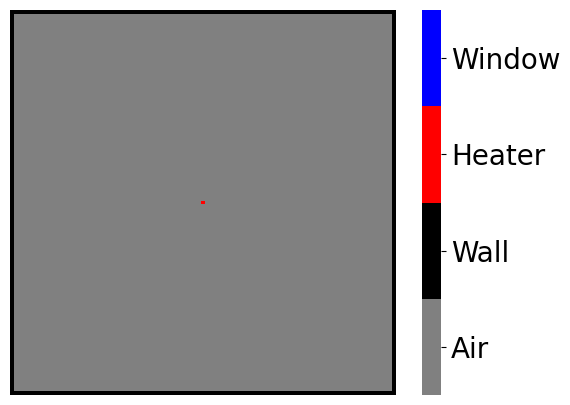

In [12]:
#Validation map
#one heater at the center
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
C.radiator(int(size/2),int(size/2))
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
map_plot(C.matrix,size)

In [13]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot1,energy1=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot1),i=(0,len(Tplot1)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

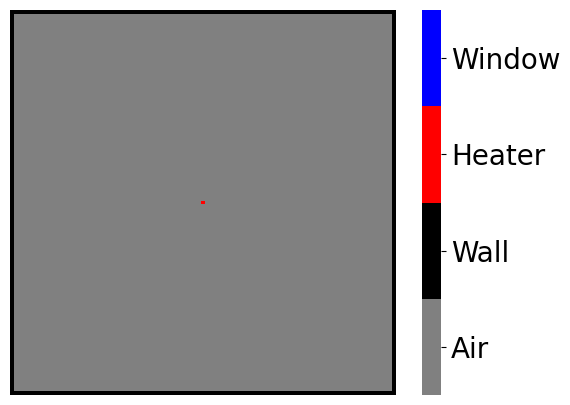

In [14]:
datasaver(Tplot1,C,"sperical.pdf",500,size)

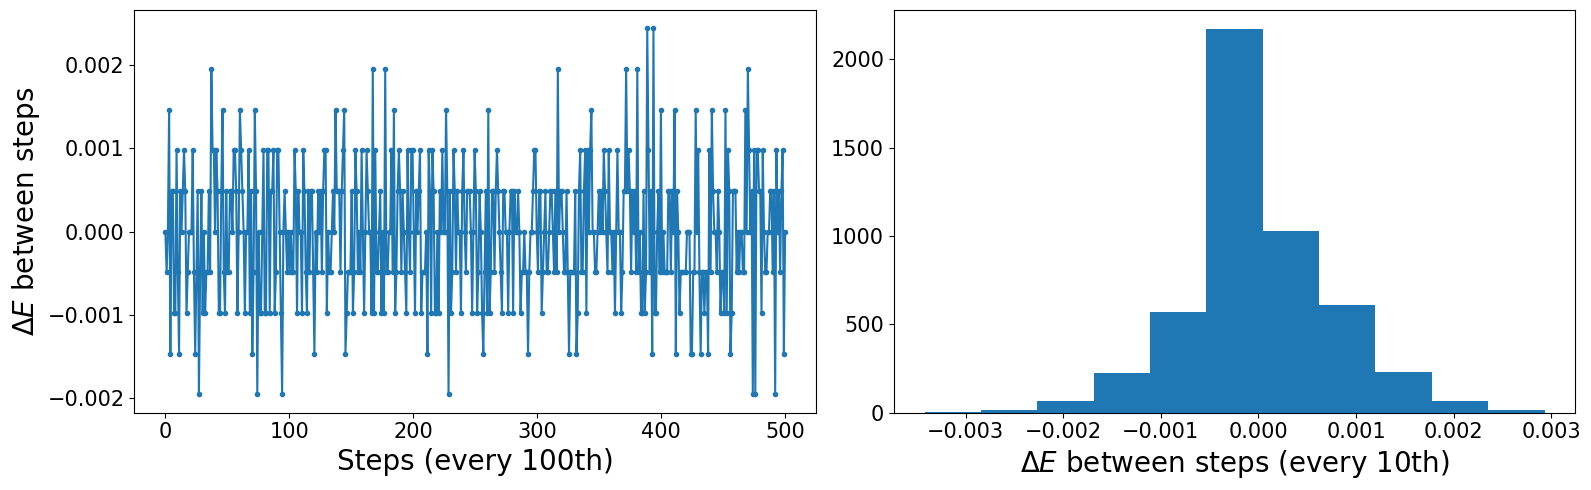

In [23]:
#energy difference and histogram plots
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
dE1=energy1[:-1:10]-energy1[1::10]
plt.plot(np.linspace(0,len(dE1),len(dE1)),dE1,marker=".",linestyle="-")
plt.xlabel("Steps (every 100th)",fontsize=20,)
plt.ylabel(r"$\Delta E$ between steps",fontsize=20);
plt.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout()
plt.subplot(1,2,2)
plt.hist(energy1[:-1]-energy1[1:],bins=11)
plt.xlabel(r"$\Delta E$ between steps (every 10th)",fontsize=20);
plt.tick_params(axis='both', which='major', labelsize=15);
plt.tight_layout()
plt.savefig(filepath+"energy.pdf")

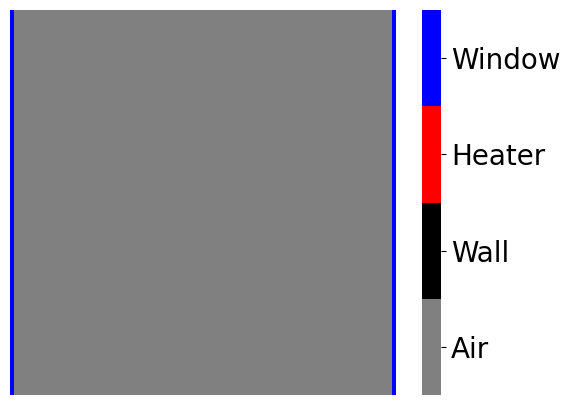

In [16]:
#Validation map
#windows on the side
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.window(i,0)
    C.window(i,size-1)
map_plot(C.matrix,size)

In [17]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot2,energy2=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot2),i=(0,len(Tplot2)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

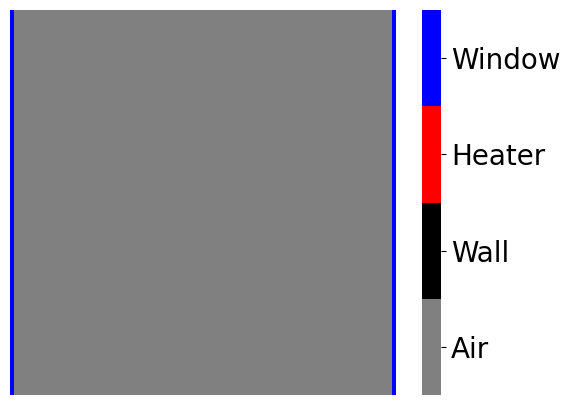

In [18]:
datasaver(Tplot2,C,"rod.pdf",500,size)

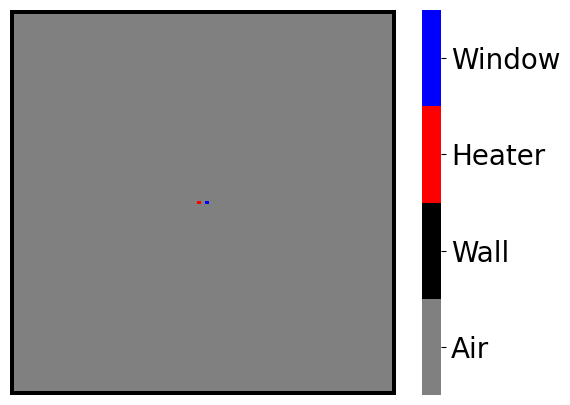

In [19]:
#Validation map
#a "dipole" of heaters and windows
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.window(int(size/2),int(size/2)+1)
C.radiator(int(size/2),int(size/2)-1)
map_plot(C.matrix,size)

In [20]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,250,350)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot3,energy3=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot3),i=(0,len(Tplot3)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

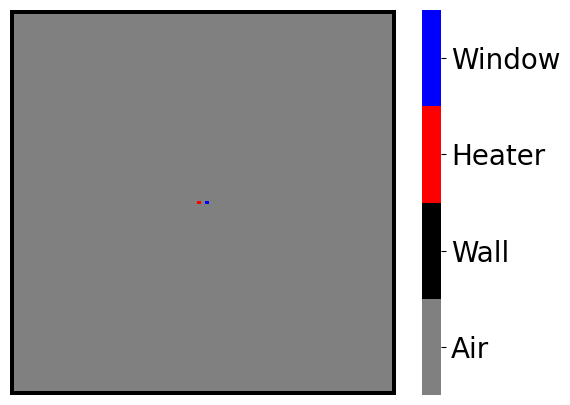

In [21]:
datasaver(Tplot3,C,"dipole.pdf",500,size)

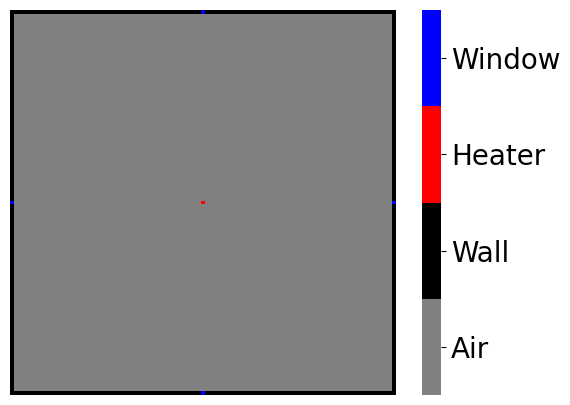

In [24]:
#4 windows and a heater at the center
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),int(size/2))
C.window(0,int(size/2))
C.window(int(size/2),0)
C.window(size-1,int(size/2))
C.window(int(size/2),size-1)
map_plot(C.matrix,size)

In [25]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot4,energy4=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot4),i=(0,len(Tplot4)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

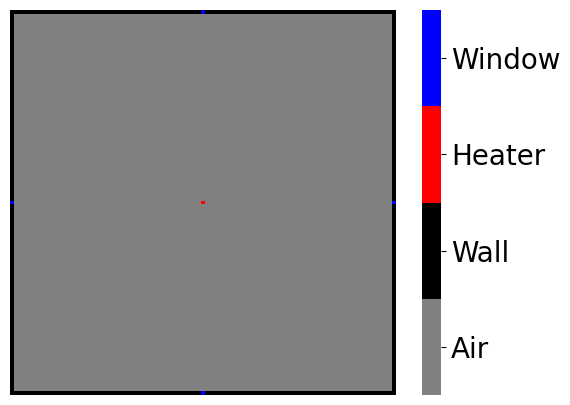

In [26]:
datasaver(Tplot4,C,"4windows.pdf",500,size)

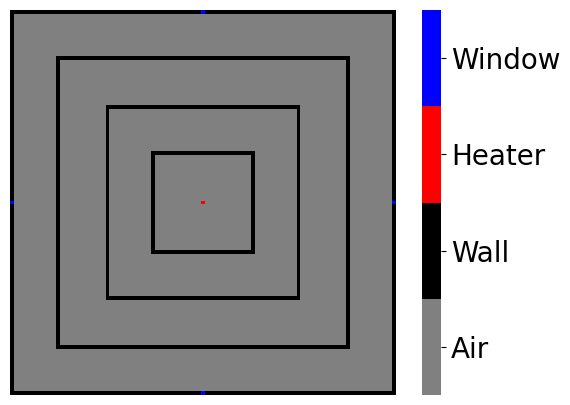

In [27]:
#A square configuration of walls with 4 windows and a heater at the center
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),int(size/2))
C.window(0,int(size/2))
C.window(int(size/2),0)
C.window(size-1,int(size/2))
C.window(int(size/2),size-1)

square_side=int(size/8*3)
for i in range(0,size-1):
    C.wall(square_side,i)
    C.wall(i,square_side)
    C.wall(size-square_side-1,i)
    C.wall(i,size-square_side-1)
for i in range(1,square_side):
    C.air(square_side,i)
    C.air(i,square_side)
    C.air(size-square_side-1,i)
    C.air(i,size-square_side-1)
    C.air(square_side,size-1-i)
    C.air(size-1-i,square_side)
    C.air(size-square_side-1,size-1-i)
    C.air(size-1-i,size-square_side-1)

square_side=int(size/4)
for i in range(0,size-1):
    C.wall(square_side,i)
    C.wall(i,square_side)
    C.wall(size-square_side-1,i)
    C.wall(i,size-square_side-1)
for i in range(1,square_side):
    C.air(square_side,i)
    C.air(i,square_side)
    C.air(size-square_side-1,i)
    C.air(i,size-square_side-1)
    C.air(square_side,size-1-i)
    C.air(size-1-i,square_side)
    C.air(size-square_side-1,size-1-i)
    C.air(size-1-i,size-square_side-1)

square_side=int(size/8)
for i in range(0,size-1):
    C.wall(square_side,i)
    C.wall(i,square_side)
    C.wall(size-square_side-1,i)
    C.wall(i,size-square_side-1)
for i in range(1,square_side):
    C.air(square_side,i)
    C.air(i,square_side)
    C.air(size-square_side-1,i)
    C.air(i,size-square_side-1)
    C.air(square_side,size-1-i)
    C.air(size-1-i,square_side)
    C.air(size-square_side-1,size-1-i)
    C.air(size-1-i,size-square_side-1)

map_plot(C.matrix,size)

In [28]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot5,energy5=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot5),i=(0,len(Tplot5)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

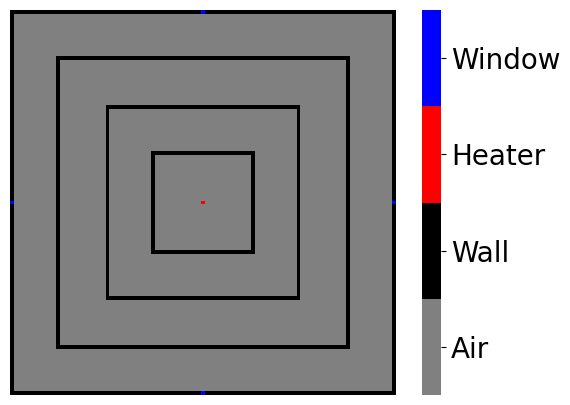

In [29]:
datasaver(Tplot5,C,"4windows+squarewalls.pdf",500,size)

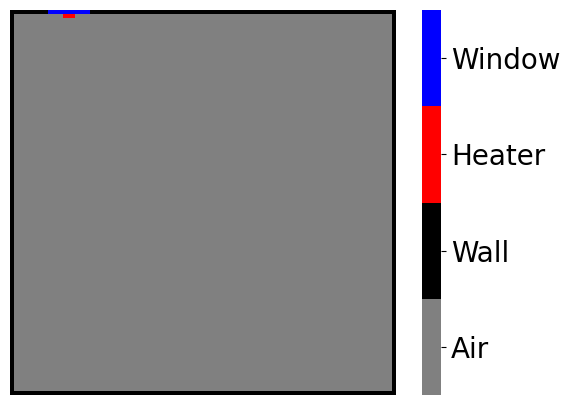

In [30]:
#Another configuration with a window negating the effect of the heater
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
for i in range(11):
    C.window(0,10+i)
C.radiator(1,14)
C.radiator(1,15)
C.radiator(1,16)
map_plot(C.matrix,size)

In [31]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot6,energy6=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot6),i=(0,len(Tplot6)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

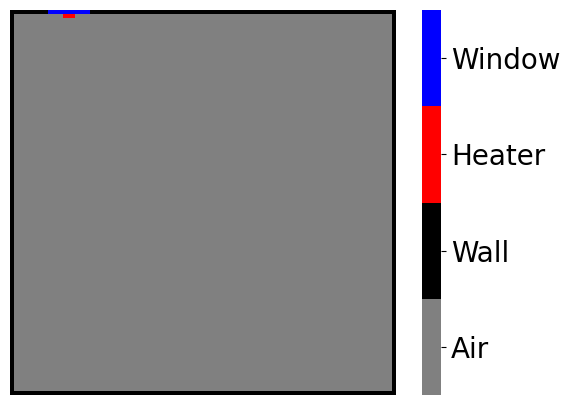

In [32]:
datasaver(Tplot6,C,"heat_under_win.pdf",500,size)

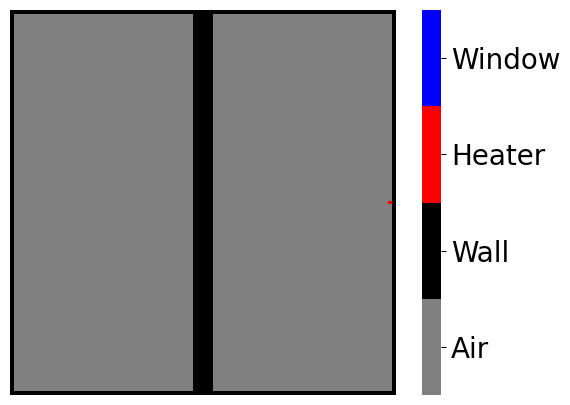

In [33]:
#custom setup
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),size-2)
for i in range(size): #int(size/5),
    C.wall(i,int(size/2))
    C.wall(i,int(size/2)-1)
    C.wall(i,int(size/2)+1)
    C.wall(i,int(size/2)-2)
    C.wall(i,int(size/2)+2)
    #C.wall(i,int(size/2)-4)
    #C.wall(i,int(size/2)+4)
    #C.wall(i,int(size/2)-6)
    #C.wall(i,int(size/2)+6)
    #C.wall(i,int(size/2)-8)
    #C.wall(i,int(size/2)+8)
    #C.wall(i,int(size/2)-10)
    #C.wall(i,int(size/2)+10)
map_plot(C.matrix,size)

In [34]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot,energy=timeevolve(C.matrix,T0,K_horiz,K_vert,100000,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot),i=(0,len(Tplot)-1,1),size=fixed(size));

0% 1% 2% 3% 4% 5% 6% 7% 8% 9% 10% 11% 12% 13% 14% 15% 16% 17% 18% 19% 20% 21% 22% 23% 24% 25% 26% 27% 28% 29% 30% 31% 32% 33% 34% 35% 36% 37% 38% 39% 40% 41% 42% 43% 44% 45% 46% 47% 48% 49% 50% 51% 52% 53% 54% 55% 56% 57% 58% 59% 60% 61% 62% 63% 64% 65% 66% 67% 68% 69% 70% 71% 72% 73% 74% 75% 76% 77% 78% 79% 80% 81% 82% 83% 84% 85% 86% 87% 88% 89% 90% 91% 92% 93% 94% 95% 96% 97% 98% 99% 

interactive(children=(IntSlider(value=4999, description='i', max=9999), Output()), _dom_classes=('widget-inter…

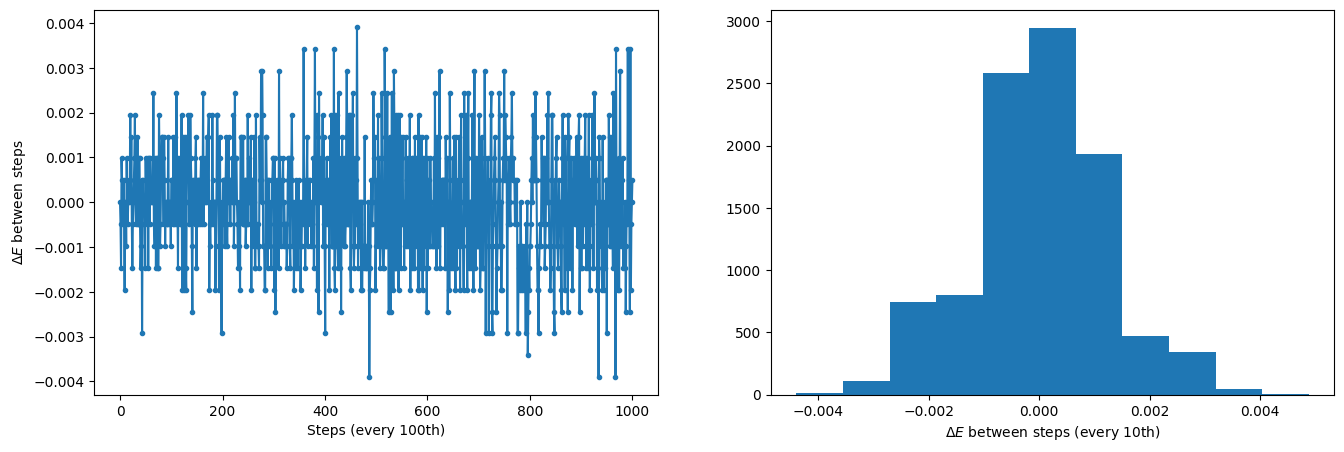

In [35]:
#energy difference and histogram plots
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
dE=energy[:-1:10]-energy[1::10]
plt.plot(np.linspace(0,len(dE),len(dE)),dE,marker=".",linestyle="-")
plt.xlabel("Steps (every 100th)")
plt.ylabel(r"$\Delta E$ between steps");
plt.subplot(1,2,2)
plt.hist(energy[:-1]-energy[1:],bins=11)
plt.xlabel(r"$\Delta E$ between steps (every 10th)");
#plt.savefig(filepath+"energy.pdf")

0th 1000th 2000th 3000th 4000th 5000th 6000th 7000th 8000th 9000th 

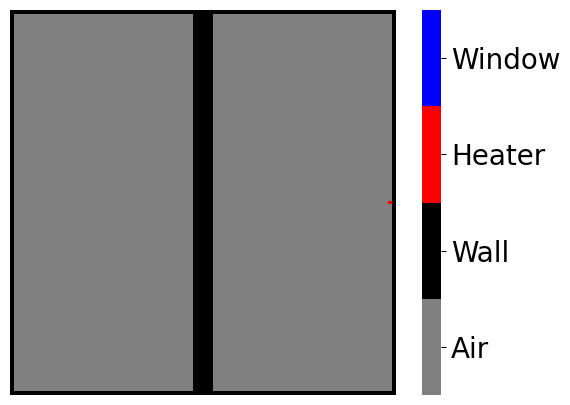

In [36]:
#saving the previous time evolution
datasaver(Tplot,C,"walls5.pdf",1000,size)

0% 1% 2% 3% 4% 5% 6% 7% 8% 9% 10% 11% 12% 13% 14% 15% 16% 17% 18% 19% 20% 21% 22% 23% 24% 25% 26% 27% 28% 29% 30% 31% 32% 33% 34% 35% 36% 37% 38% 39% 40% 41% 42% 43% 44% 45% 46% 47% 48% 49% 50% 51% 52% 53% 54% 55% 56% 57% 58% 59% 60% 61% 62% 63% 64% 65% 66% 67% 68% 69% 70% 71% 72% 73% 74% 75% 76% 77% 78% 79% 80% 81% 82% 83% 84% 85% 86% 87% 88% 89% 90% 91% 92% 93% 94% 95% 96% 97% 98% 99% 

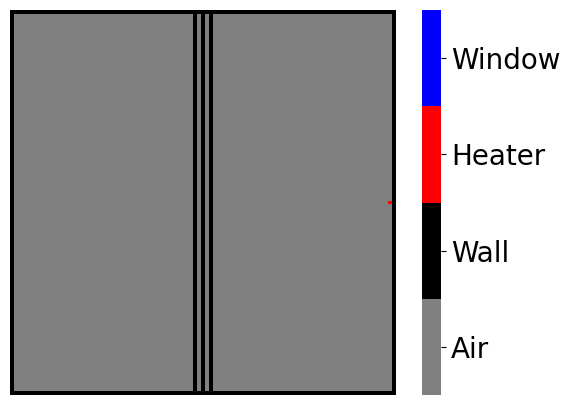

interactive(children=(IntSlider(value=4999, description='i', max=9999), Output()), _dom_classes=('widget-inter…

0th 1000th 2000th 3000th 4000th 5000th 6000th 7000th 8000th 9000th 

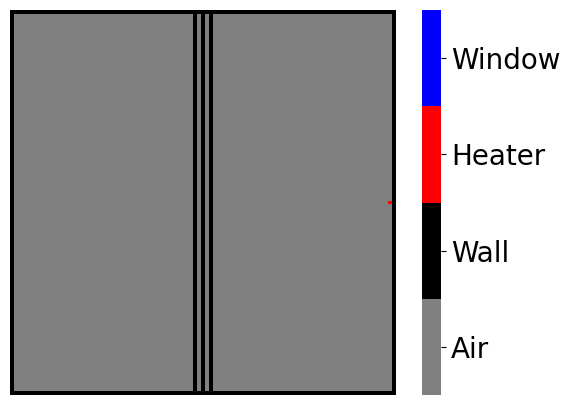

In [37]:
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),size-2)
for i in range(size): #int(size/5),
    C.wall(i,int(size/2))
    #C.wall(i,int(size/2)-1)
    #C.wall(i,int(size/2)+1)
    C.wall(i,int(size/2)-2)
    C.wall(i,int(size/2)+2)
    #C.wall(i,int(size/2)-4)
    #C.wall(i,int(size/2)+4)
    #C.wall(i,int(size/2)-6)
    #C.wall(i,int(size/2)+6)
    #C.wall(i,int(size/2)-8)
    #C.wall(i,int(size/2)+8)
    #C.wall(i,int(size/2)-10)
    #C.wall(i,int(size/2)+10)
map_plot(C.matrix,size)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot,energy=timeevolve(C.matrix,T0,K_horiz,K_vert,100000,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot),i=(0,len(Tplot)-1,1),size=fixed(size));
datasaver(Tplot,C,"walls+2.pdf",1000,size)

0% 1% 2% 3% 4% 5% 6% 7% 8% 9% 10% 11% 12% 13% 14% 15% 16% 17% 18% 19% 20% 21% 22% 23% 24% 25% 26% 27% 28% 29% 30% 31% 32% 33% 34% 35% 36% 37% 38% 39% 40% 41% 42% 43% 44% 45% 46% 47% 48% 49% 50% 51% 52% 53% 54% 55% 56% 57% 58% 59% 60% 61% 62% 63% 64% 65% 66% 67% 68% 69% 70% 71% 72% 73% 74% 75% 76% 77% 78% 79% 80% 81% 82% 83% 84% 85% 86% 87% 88% 89% 90% 91% 92% 93% 94% 95% 96% 97% 98% 99% 

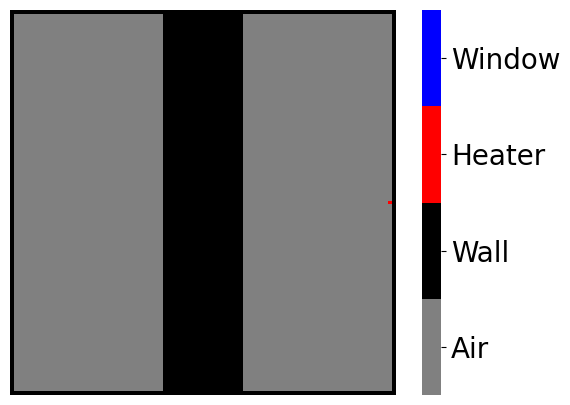

interactive(children=(IntSlider(value=4999, description='i', max=9999), Output()), _dom_classes=('widget-inter…

0th 1000th 2000th 3000th 4000th 5000th 6000th 7000th 8000th 9000th 

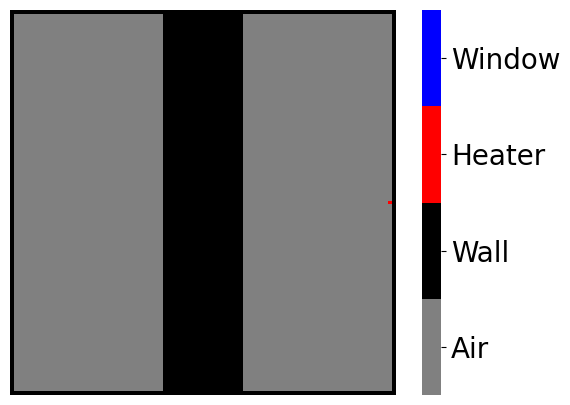

In [38]:
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),size-2)
for i in range(size): #int(size/5),
    C.wall(i,int(size/2))
    C.wall(i,int(size/2)-1)
    C.wall(i,int(size/2)+1)
    C.wall(i,int(size/2)-2)
    C.wall(i,int(size/2)+2)
    C.wall(i,int(size/2)-4)
    C.wall(i,int(size/2)+4)
    C.wall(i,int(size/2)-3)
    C.wall(i,int(size/2)+3)
    C.wall(i,int(size/2)-5)
    C.wall(i,int(size/2)+5)
    C.wall(i,int(size/2)-6)
    C.wall(i,int(size/2)+6)
    C.wall(i,int(size/2)-7)
    C.wall(i,int(size/2)+7)
    C.wall(i,int(size/2)-8)
    C.wall(i,int(size/2)+8)
    C.wall(i,int(size/2)-9)
    C.wall(i,int(size/2)+9)
    C.wall(i,int(size/2)-10)
    C.wall(i,int(size/2)+10)
map_plot(C.matrix,size)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot,energy=timeevolve(C.matrix,T0,K_horiz,K_vert,100000,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot),i=(0,len(Tplot)-1,1),size=fixed(size));
datasaver(Tplot,C,"walls21.pdf",1000,size)

0% 1% 2% 3% 4% 5% 6% 7% 8% 9% 10% 11% 12% 13% 14% 15% 16% 17% 18% 19% 20% 21% 22% 23% 24% 25% 26% 27% 28% 29% 30% 31% 32% 33% 34% 35% 36% 37% 38% 39% 40% 41% 42% 43% 44% 45% 46% 47% 48% 49% 50% 51% 52% 53% 54% 55% 56% 57% 58% 59% 60% 61% 62% 63% 64% 65% 66% 67% 68% 69% 70% 71% 72% 73% 74% 75% 76% 77% 78% 79% 80% 81% 82% 83% 84% 85% 86% 87% 88% 89% 90% 91% 92% 93% 94% 95% 96% 97% 98% 99% 

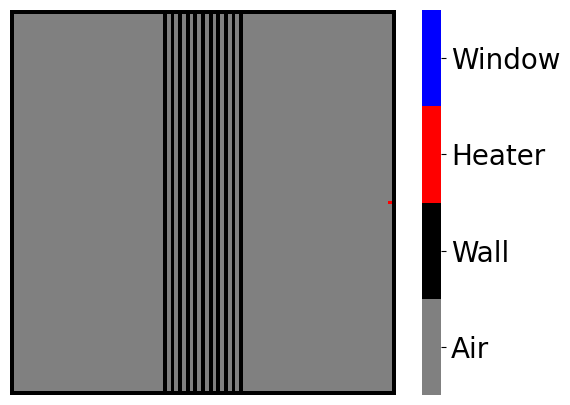

interactive(children=(IntSlider(value=4999, description='i', max=9999), Output()), _dom_classes=('widget-inter…

0th 1000th 2000th 3000th 4000th 5000th 6000th 7000th 8000th 9000th 

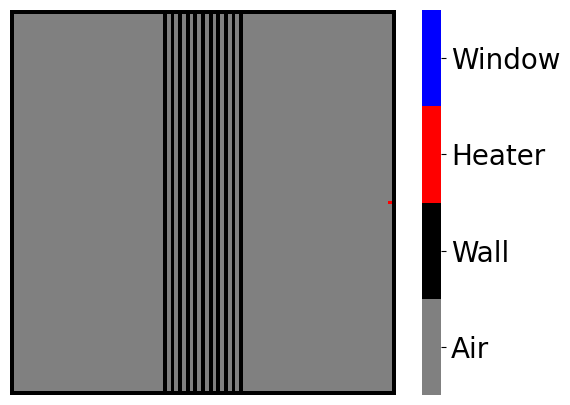

In [39]:
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(size-1,i)
    C.wall(i,size-1)
C.radiator(int(size/2),size-2)
for i in range(size): #int(size/5),
    C.wall(i,int(size/2))
    C.wall(i,int(size/2)-2)
    C.wall(i,int(size/2)+2)
    C.wall(i,int(size/2)-4)
    C.wall(i,int(size/2)+4)
    C.wall(i,int(size/2)-6)
    C.wall(i,int(size/2)+6)
    C.wall(i,int(size/2)-8)
    C.wall(i,int(size/2)+8)
    C.wall(i,int(size/2)-10)
    C.wall(i,int(size/2)+10)
map_plot(C.matrix,size)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot,energy=timeevolve(C.matrix,T0,K_horiz,K_vert,100000,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot),i=(0,len(Tplot)-1,1),size=fixed(size));
datasaver(Tplot,C,"walls+10.pdf",1000,size)

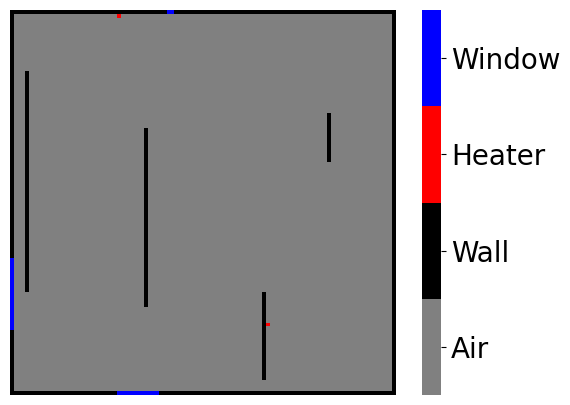

In [55]:
#creating a random initial map
C_rand=randommap(size,C_wall,C_rad,C_air,C_window)
map_plot(C_rand.matrix,size)

In [56]:
#calling the initialization and time evolving functions and creating an interactive heatmap of the time evolution
T0=initaltemp(C_rand.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C_rand.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C_rand.matrix,Cvect,heattransf)
Tplot_rand,energy_rand=timeevolve(C_rand.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_rand),i=(0,len(Tplot_rand)-1,1),size=fixed(size));

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

0th 500th 1000th 1500th 2000th 2500th 3000th 3500th 4000th 4500th 

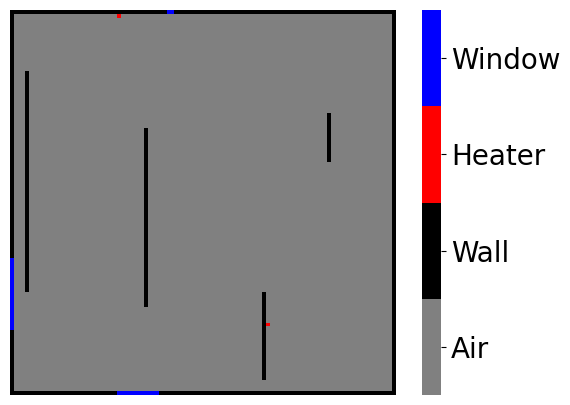

In [57]:
#saving the random maps time evolution
datasaver(Tplot_rand,C_rand,"random.pdf",500,size)

In [ ]:
#time=1
#maps=[]
#timeevolves=[]
#for i in range(time):
#    map=randommap(size,C_wall,C_rad,C_air,C_window)
#    T0=initaltemp(map.matrix,Cvect)
#    K_horiz=heattransfer_horiz(map.matrix,Cvect,heattransf)
#    K_vert=heattransfer_vert(map.matrix,Cvect,heattransf)
#    timedep=timeevolve(map.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
#    maps.append(map)
#    timeevolves.append(timedep)
#np.savetxt("maps.txt",np.array(maps),fmt="%10.5f")
#np.savetxt("times.txt",np.array(timeevolves),fmt="%10.5f")

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

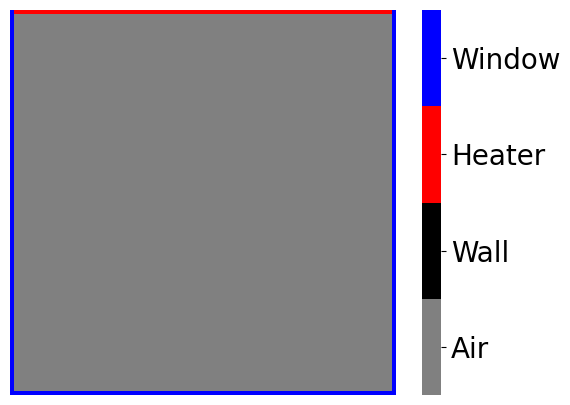

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

In [48]:
C=heatcapacity(size,C_wall,C_rad,C_air,C_window)
for i in range(size):
    C.radiator(0,i-1)
    C.window(i-1,0)
    C.window(size-1,i)
    C.window(i,size-1)
map_plot(C.matrix,size)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot_bench,energy_bench=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_bench),i=(0,len(Tplot_bench)-1,1),size=fixed(size));

0th 1000th 2000th 3000th 4000th 

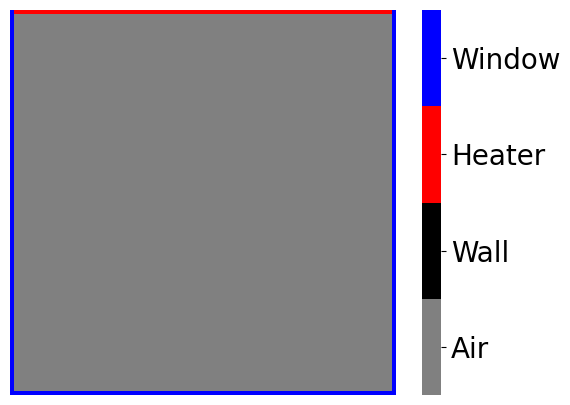

In [49]:
datasaver(Tplot_bench,C,"benchmark.pdf",1000,size)

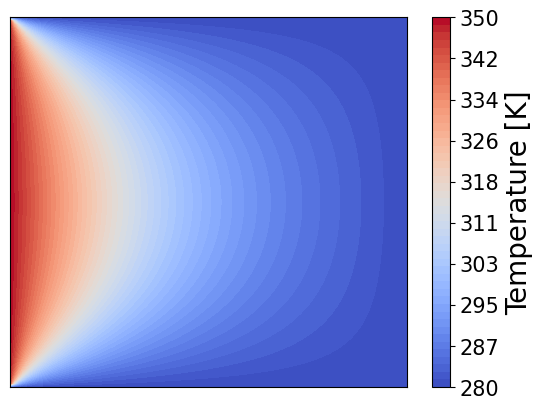

In [41]:
# Parameters
T0 = 70.0
N_terms = 100
nx, ny = 101, 101

x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
X, Y = np.meshgrid(x, y,indexing="ij")

# Analytical solution
T_series = np.zeros_like(X)
for n in range(N_terms):
    m = 2 * n + 1
    term = (1/m) * np.sinh(m * np.pi * (1-X)) / np.sinh(m * np.pi) * np.sin(m * np.pi * Y)
    T_series += term

T = 4 * T0 / np.pi * T_series + 280.0   # baseline [K]

# Plot
n_level=50
levels = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), n_level)
cp = plt.contourf(X, Y, T, levels=levels, cmap='coolwarm', vmin=min([Twindow,Twall,Tair,Trad]), vmax=max([Twindow,Twall,Tair,Trad]),origin="upper")

# Colorbar with 10 ticks
ticks = np.linspace(min([Twindow,Twall,Tair,Trad]), max([Twindow,Twall,Tair,Trad]), 10)
cbar = plt.colorbar(cp, ticks=ticks)
cbar.set_label('Temperature [K]', fontsize=20)
cbar.set_ticklabels([f"{int(t)}" for t in ticks])
cbar.ax.tick_params(labelsize=15)
plt.gca().invert_yaxis()
plt.xticks([])
plt.yticks([])
#plt.savefig(filepath+"analitic.pdf")

plt.show()

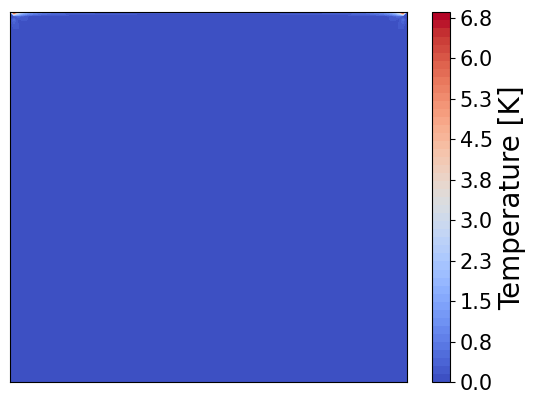

0.009003695063465657


In [44]:
delta_T=abs(T-Tplot_bench[-1])
#print(np.mean(delta_T))

x = np.linspace(0, 1, nx)
y = np.linspace(0, 1, ny)
X, Y = np.meshgrid(x, y)

# Plot
cp = plt.contourf(X, Y, delta_T, levels=50, cmap='coolwarm', vmin=delta_T.min(), vmax=delta_T.max(),origin="upper")

# Colorbar with 10 ticks
ticks = np.linspace(delta_T.min(), delta_T.max(), 10)
cbar = plt.colorbar(cp, ticks=ticks)
cbar.set_label('Temperature [K]', fontsize=20)
cbar.set_ticklabels([f"{round(t,1)}" for t in ticks])
cbar.ax.tick_params(labelsize=15)
plt.gca().invert_yaxis()
plt.xticks([])
plt.yticks([])
plt.savefig(filepath+"error.pdf")

plt.show()
print(np.mean(delta_T))

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

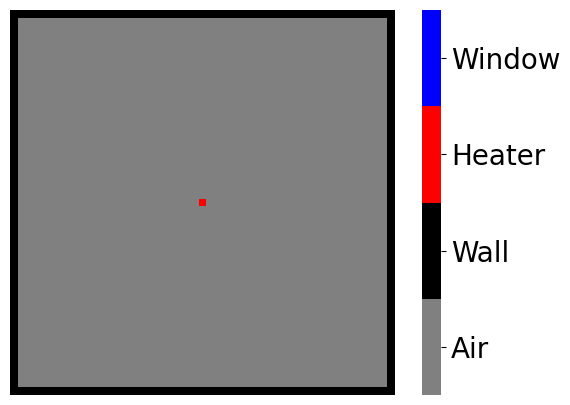

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

In [6]:
C=heatcapacity(51,C_wall,C_rad,C_air,C_window)
C.radiator(int(51/2),int(51/2))
for i in range(51):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(51-1,i)
    C.wall(i,51-1)
map_plot(C.matrix,51)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot_size,energy_size=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_size),i=(0,len(Tplot_size)-1,1),size=fixed(51));

0th 1000th 2000th 3000th 4000th 

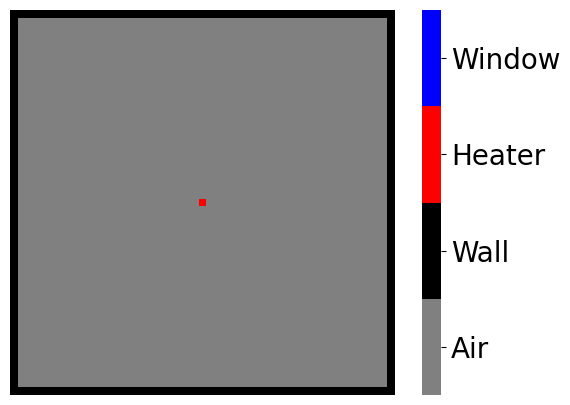

In [7]:
datasaver(Tplot_size,C,"size_51.pdf",1000,51)

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

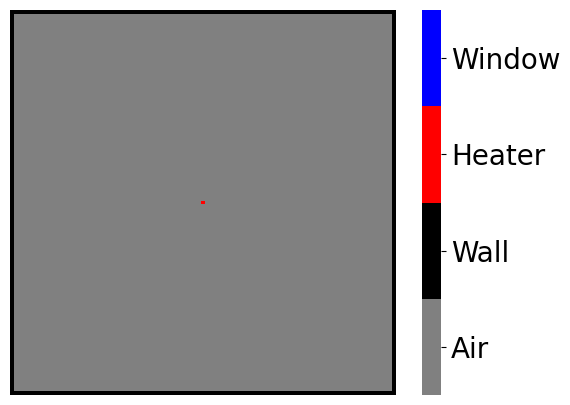

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

In [8]:
C=heatcapacity(101,C_wall,C_rad,C_air,C_window)
C.radiator(int(101/2),int(101/2))
for i in range(101):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(101-1,i)
    C.wall(i,101-1)
map_plot(C.matrix,101)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot_size,energy_size=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_size),i=(0,len(Tplot_size)-1,1),size=fixed(101));

0th 1000th 2000th 3000th 4000th 

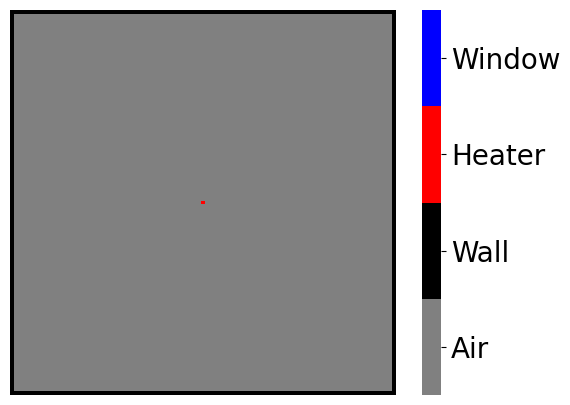

In [9]:
datasaver(Tplot_size,C,"size_101.pdf",1000,101)

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

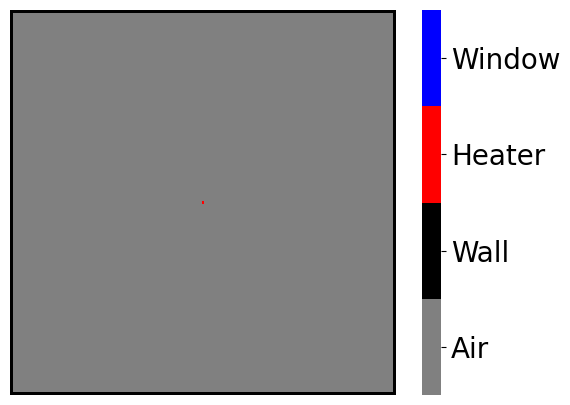

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

In [10]:
C=heatcapacity(151,C_wall,C_rad,C_air,C_window)
C.radiator(int(151/2),int(151/2))
for i in range(151):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(151-1,i)
    C.wall(i,151-1)
map_plot(C.matrix,151)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot_size,energy_size=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_size),i=(0,len(Tplot_size)-1,1),size=fixed(151));

0th 1000th 2000th 3000th 4000th 

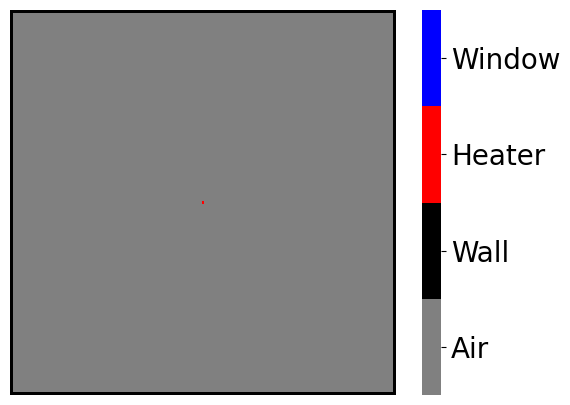

In [11]:
datasaver(Tplot_size,C,"size_151.pdf",1000,151)

0% 2% 4% 6% 8% 10% 12% 14% 16% 18% 20% 22% 24% 26% 28% 30% 32% 34% 36% 38% 40% 42% 44% 46% 48% 50% 52% 54% 56% 58% 60% 62% 64% 66% 68% 70% 72% 74% 76% 78% 80% 82% 84% 86% 88% 90% 92% 94% 96% 98% 

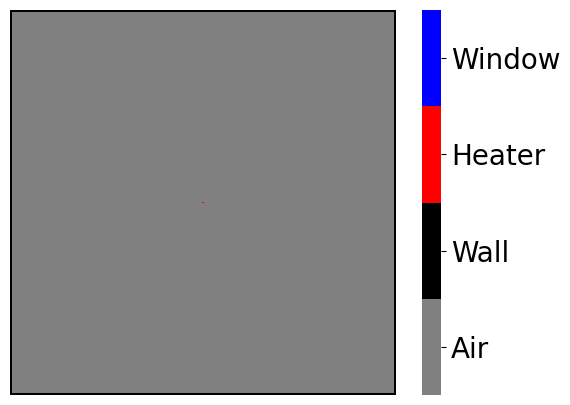

interactive(children=(IntSlider(value=2499, description='i', max=4999), Output()), _dom_classes=('widget-inter…

In [12]:
C=heatcapacity(201,C_wall,C_rad,C_air,C_window)
C.radiator(int(201/2),int(201/2))
for i in range(201):
    C.wall(0,i-1)
    C.wall(i-1,0)
    C.wall(201-1,i)
    C.wall(i,201-1)
map_plot(C.matrix,201)
T0=initaltemp(C.matrix,Cvect,Twall,Tair,Twindow,Trad)
K_horiz=heattransfer_horiz(C.matrix,Cvect,heattransf)
K_vert=heattransfer_vert(C.matrix,Cvect,heattransf)
Tplot_size,energy_size=timeevolve(C.matrix,T0,K_horiz,K_vert,totaltime,save,dt,dx,dy)
interact(ploti,plot=fixed(Tplot_size),i=(0,len(Tplot_size)-1,1),size=fixed(201));

0th 1000th 2000th 3000th 4000th 

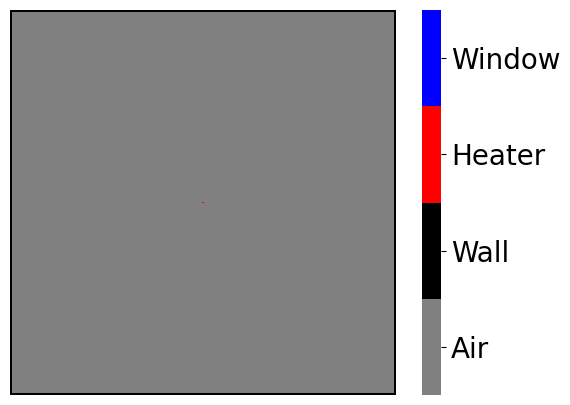

In [13]:
datasaver(Tplot_size,C,"size_201.pdf",1000,201)